# PRCP-1006 – Home Loan Default Prediction

## Domain: Banking

### Project Objective

The objective of this project is to perform a complete data analysis
on home loan application data and develop a predictive machine learning
model to identify customers who are likely to default on their loans.

The project also aims to identify important factors and customer
segments associated with loan default and compare the performance of
multiple machine learning models to recommend the best model for
production.

## Problem Statement

The banking sector needs to assess the credit risk associated with
customers applying for loans.

In this project, we analyze customer application information along
with their previous credit history, previous loan applications,
repayment behavior, credit card history, and POS/cash loan history.

The target variable is:

- 0 → Not Defaulter
- 1 → Defaulter

The objective is to build a machine learning classification model
that can predict whether an applicant is likely to default.

## Dataset Description

The project contains the following datasets:

1. application_train.csv
2. bureau.csv
3. bureau_balance.csv
4. POS_CASH_balance.csv
5. credit_card_balance.csv
6. previous_application.csv
7. installments_payments.csv

The application_train.csv file contains the main loan application
information and the target variable.

The other datasets contain historical credit and repayment
information of the applicants.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
application = pd.read_csv("application_train.csv")

print("Application dataset loaded successfully!")
print("Shape:", application.shape)

Application dataset loaded successfully!
Shape: (307511, 122)


In [3]:
print("Rows:", application.shape[0])
print("Columns:", application.shape[1])

print("\nData types:")
print(application.dtypes.value_counts())

print("\nMissing values:")
print(application.isnull().sum().sum())

print("\nDuplicate rows:")
print(application.duplicated().sum())

print("\nTarget distribution:")
print(application["TARGET"].value_counts())

Rows: 307511
Columns: 122

Data types:
float64    65
int64      41
object     16
Name: count, dtype: int64

Missing values:
9152465

Duplicate rows:
0

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64


In [4]:
target_distribution = application["TARGET"].value_counts()

target_percentage = (
    application["TARGET"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Target counts:")
print(target_distribution)

print("\nTarget percentages:")
print(target_percentage)

Target counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


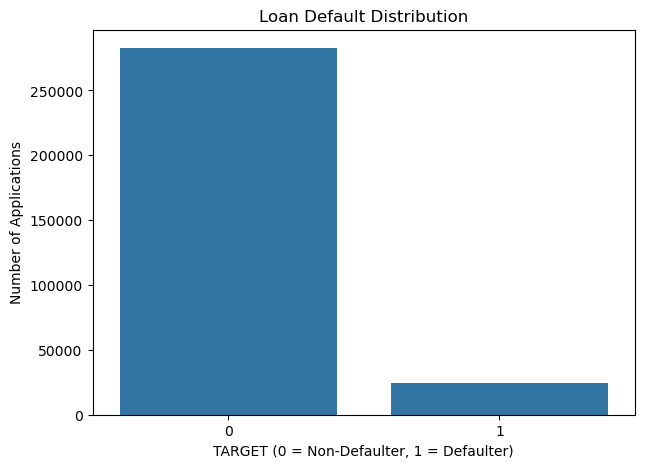

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=application,
    x="TARGET"
)

plt.title("Loan Default Distribution")
plt.xlabel("TARGET (0 = Non-Defaulter, 1 = Defaulter)")
plt.ylabel("Number of Applications")

plt.show()

In [6]:
pd.set_option("display.max_rows", 200)

feature_info = pd.DataFrame({
    "Feature": application.columns,
    "Data_Type": application.dtypes.values,
    "Unique_Values": [
        application[col].nunique()
        for col in application.columns
    ],
    "Missing_Values": [
        application[col].isna().sum()
        for col in application.columns
    ]
})

feature_info

,Feature,Data_Type,Unique_Values,Missing_Values
0,SK_ID_CURR,int64,307511,0
1,TARGET,int64,2,0
2,NAME_CONTRACT_TYPE,object,2,0
3,CODE_GENDER,object,3,0
4,FLAG_OWN_CAR,object,2,0
5,FLAG_OWN_REALTY,object,2,0
6,CNT_CHILDREN,int64,15,0
7,AMT_INCOME_TOTAL,float64,2548,0
8,AMT_CREDIT,float64,5603,0
9,AMT_ANNUITY,float64,13672,12


In [7]:
numerical_features = application.select_dtypes(
    include=np.number
).columns.tolist()

print("Number of numerical features:",
      len(numerical_features))

Number of numerical features: 106


In [8]:
categorical_features = application.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical features:",
      len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

Number of categorical features: 16

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [9]:
missing_summary = pd.DataFrame({
    "Missing_Count": application.isnull().sum(),
    "Missing_Percentage": (
        application.isnull().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary.head(20)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


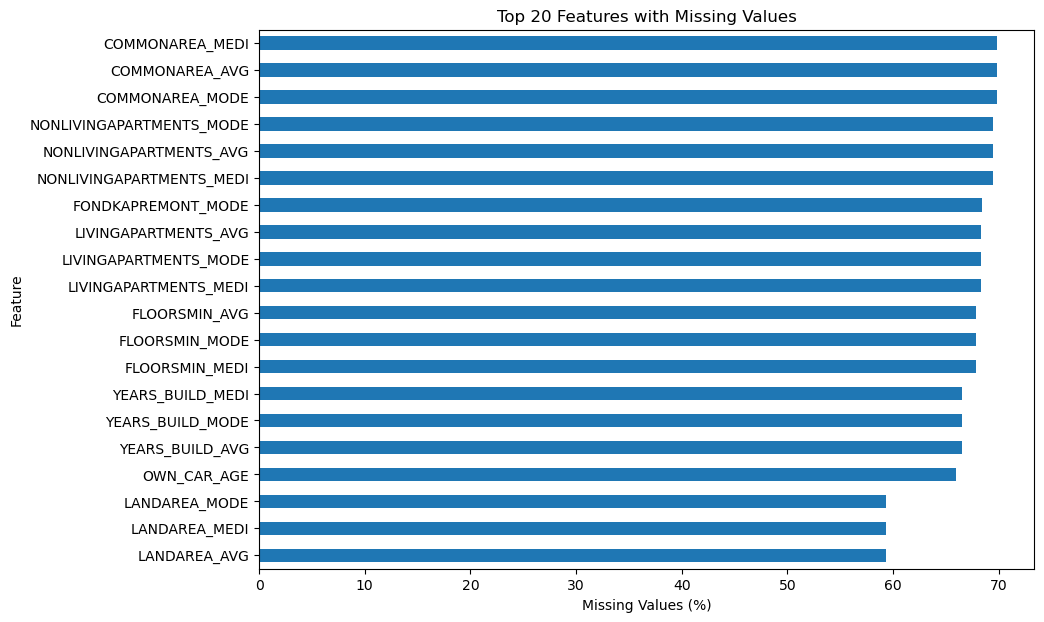

In [10]:
plt.figure(figsize=(10, 7))

missing_summary.head(20)["Missing_Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")

plt.show()

In [11]:
application.describe()

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,1.000020e+05,189145.500000,278202.000000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.000000e+00,0.000000,0.000000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.000000e+00,0.000000,0.000000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,4.500000e+04,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1.615500e+03,16524.000000,24903.000000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,4.050000e+04,238500.000000,450000.000000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,2.900000e-04,0.010006,0.018850,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-1.791200e+04,-2760.000000,-1213.000000,-289.000000,3.652430e+05


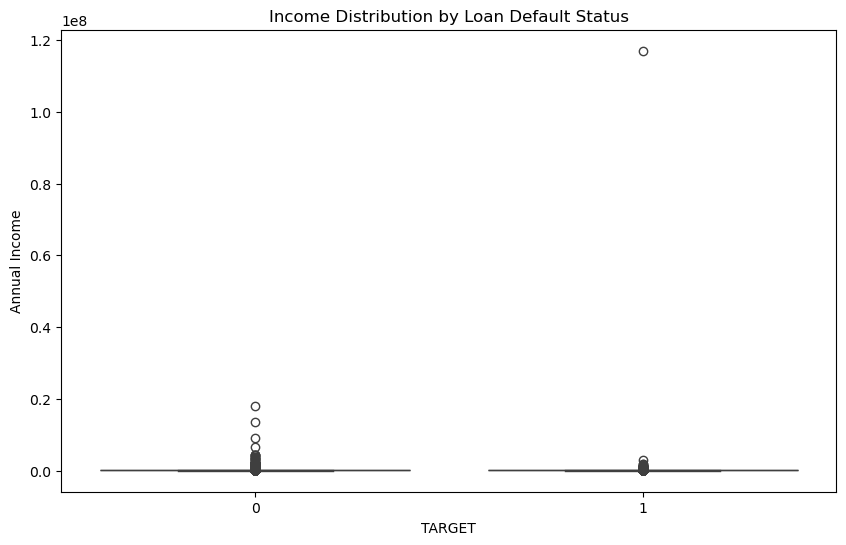

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=application,
    x="TARGET",
    y="AMT_INCOME_TOTAL"
)

plt.title("Income Distribution by Loan Default Status")
plt.xlabel("TARGET")
plt.ylabel("Annual Income")

plt.show()

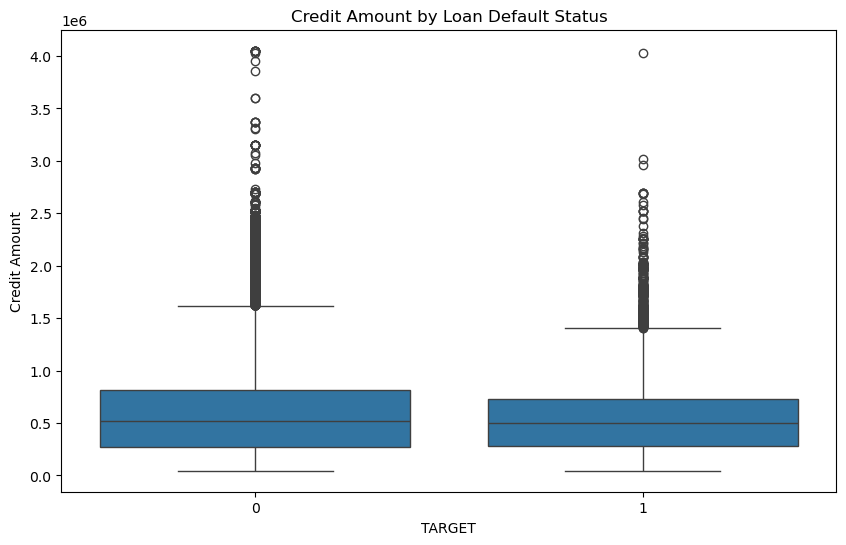

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=application,
    x="TARGET",
    y="AMT_CREDIT"
)

plt.title("Credit Amount by Loan Default Status")
plt.xlabel("TARGET")
plt.ylabel("Credit Amount")

plt.show()

In [14]:
default_rate = application["TARGET"].mean()

print("Default rate:", default_rate)
print("Default rate (%):", default_rate * 100)
print("Non-default rate (%):", (1 - default_rate) * 100)

Default rate: 0.08072881945686496
Default rate (%): 8.072881945686495
Non-default rate (%): 91.92711805431351


In [15]:
X = application.drop(columns=["TARGET"])
y = application["TARGET"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (307511, 121)
Target shape: (307511,)


In [16]:
X = X.drop(columns=["SK_ID_CURR"])

print("Features after removing ID:", X.shape[1])

Features after removing ID: 120


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (184506, 120)
Validation: (61502, 120)
Test: (61503, 120)


In [18]:
print("Training default rate:")
print(y_train.mean() * 100)

print("\nValidation default rate:")
print(y_val.mean() * 100)

print("\nTest default rate:")
print(y_test.mean() * 100)

Training default rate:
8.07290819810738

Validation default rate:
8.07290819810738

Test default rate:
8.072776937710357


In [19]:
categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of categorical columns:",
      len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns)

Number of categorical columns: 16

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [20]:
!pip install catboost

In [21]:
# Make copies for CatBoost
X_train_cat = X_train.copy()
X_val_cat = X_val.copy()

# Convert categorical columns to strings
# Missing categorical values are represented as "Missing"
for col in categorical_columns:
    X_train_cat[col] = X_train_cat[col].fillna("Missing").astype(str)
    X_val_cat[col] = X_val_cat[col].fillna("Missing").astype(str)

print("Categorical columns prepared successfully!")
print("Training shape:", X_train_cat.shape)
print("Validation shape:", X_val_cat.shape)

Categorical columns prepared successfully!
Training shape: (184506, 120)
Validation shape: (61502, 120)


In [22]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=500,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_columns,
    eval_set=(X_val_cat, y_val),
    early_stopping_rounds=50
)

print("CatBoost training completed!")

0:	test: 0.6742013	best: 0.6742013 (0)	total: 968ms	remaining: 8m 3s
100:	test: 0.7476917	best: 0.7476917 (100)	total: 1m 13s	remaining: 4m 51s
200:	test: 0.7533913	best: 0.7533913 (200)	total: 2m 28s	remaining: 3m 41s
300:	test: 0.7564363	best: 0.7564363 (300)	total: 3m 42s	remaining: 2m 26s
400:	test: 0.7574269	best: 0.7574269 (400)	total: 4m 55s	remaining: 1m 13s
499:	test: 0.7582143	best: 0.7582214 (498)	total: 6m 8s	remaining: 0us

bestTest = 0.7582214223
bestIteration = 498

Shrink model to first 499 iterations.
CatBoost training completed!


In [23]:
cat_prob = cat_model.predict_proba(X_val_cat)[:, 1]

cat_pred = (cat_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_val, cat_pred))
print("Precision:", precision_score(y_val, cat_pred))
print("Recall:", recall_score(y_val, cat_pred))
print("F1 Score:", f1_score(y_val, cat_pred))
print("ROC-AUC:", roc_auc_score(y_val, cat_prob))

Accuracy: 0.9195961106955871
Precision: 0.5694444444444444
Recall: 0.01651560926485398
F1 Score: 0.03210021530632218
ROC-AUC: 0.7582214222874054


In [24]:
print("\nClassification Report:")
print(classification_report(y_val, cat_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56537
           1       0.57      0.02      0.03      4965

    accuracy                           0.92     61502
   macro avg       0.74      0.51      0.50     61502
weighted avg       0.89      0.92      0.88     61502



In [25]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

class_weight_ratio = negative / positive

print("Non-defaulters:", negative)
print("Defaulters:", positive)
print("Class weight ratio:", class_weight_ratio)

Non-defaulters: 169611
Defaulters: 14895
Class weight ratio: 11.38710976837865


In [26]:
cat_balanced = CatBoostClassifier(
    iterations=800,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    class_weights=[1, class_weight_ratio],
    random_seed=42,
    verbose=100,
    thread_count=-1
)

cat_balanced.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_columns,
    eval_set=(X_val_cat, y_val),
    early_stopping_rounds=50
)

print("Balanced CatBoost training completed!")

0:	test: 0.6992392	best: 0.6992392 (0)	total: 805ms	remaining: 10m 42s
100:	test: 0.7455844	best: 0.7455844 (100)	total: 1m 26s	remaining: 10m 1s
200:	test: 0.7512185	best: 0.7512185 (200)	total: 2m 48s	remaining: 8m 22s
300:	test: 0.7561215	best: 0.7561215 (300)	total: 4m 9s	remaining: 6m 52s
400:	test: 0.7583472	best: 0.7583617 (397)	total: 5m 32s	remaining: 5m 30s
500:	test: 0.7587249	best: 0.7588353 (468)	total: 6m 55s	remaining: 4m 7s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.7588353453
bestIteration = 468

Shrink model to first 469 iterations.
Balanced CatBoost training completed!


In [27]:
balanced_prob = cat_balanced.predict_proba(X_val_cat)[:, 1]

balanced_pred = (balanced_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_val, balanced_pred))
print("Precision:", precision_score(y_val, balanced_pred))
print("Recall:", recall_score(y_val, balanced_pred))
print("F1 Score:", f1_score(y_val, balanced_pred))
print("ROC-AUC:", roc_auc_score(y_val, balanced_prob))

Accuracy: 0.7165620630223407
Precision: 0.17200736648250461
Recall: 0.6584088620342397
F1 Score: 0.2727576136837714
ROC-AUC: 0.7588353453034642


In [28]:
print(classification_report(y_val, balanced_pred))

              precision    recall  f1-score   support

           0       0.96      0.72      0.82     56537
           1       0.17      0.66      0.27      4965

    accuracy                           0.72     61502
   macro avg       0.57      0.69      0.55     61502
weighted avg       0.90      0.72      0.78     61502



In [29]:
balanced_prob >= 0.5

array([ True,  True, False, ..., False,  True, False], shape=(61502,))

In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for threshold in thresholds:
    pred = (balanced_prob >= threshold).astype(int)
    
    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)
    accuracy = accuracy_score(y_val, pred)
    
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.121248,0.083786,0.994965,0.154556
1,0.15,0.183945,0.088693,0.982075,0.162693
2,0.20,0.263975,0.095946,0.963746,0.174517
3,0.25,0.350948,0.105131,0.937160,0.189054
4,0.30,0.435400,0.115705,0.902316,0.205109
5,0.35,0.516536,0.127769,0.856193,0.222356
6,0.40,0.590371,0.140608,0.796979,0.239043
7,0.45,0.655865,0.154201,0.727492,0.254465
8,0.50,0.716562,0.172007,0.658409,0.272758
9,0.55,0.767503,0.190106,0.576636,0.285943


In [31]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("Best threshold for F1:")
print(best_threshold_row)

Best threshold for F1:
Threshold    0.650000
Accuracy     0.846411
Precision    0.238290
Recall       0.410876
F1           0.301641
Name: 11, dtype: float64


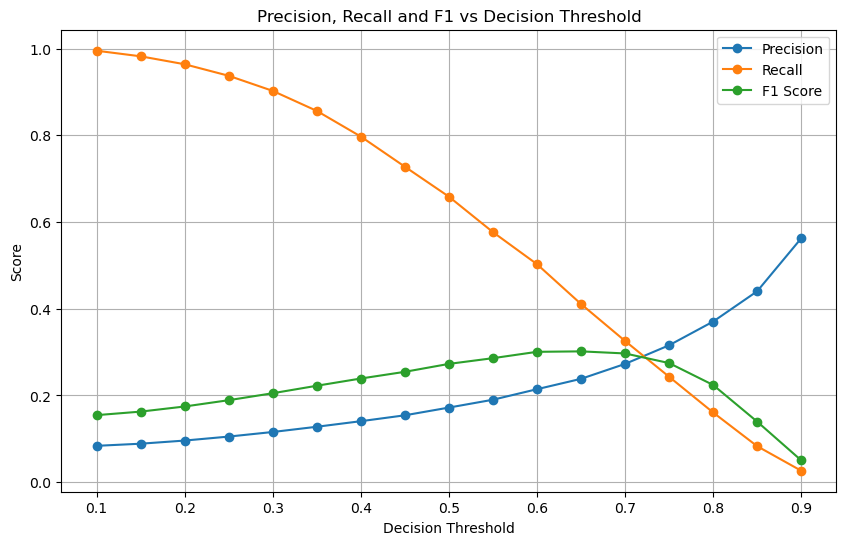

In [32]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Decision Threshold")

plt.legend()
plt.grid(True)

plt.show()

In [33]:
best_threshold = best_threshold_row["Threshold"]

optimized_pred = (
    balanced_prob >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)

print("\nAccuracy:",
      accuracy_score(y_val, optimized_pred))

print("Precision:",
      precision_score(y_val, optimized_pred))

print("Recall:",
      recall_score(y_val, optimized_pred))

print("F1 Score:",
      f1_score(y_val, optimized_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, balanced_prob))

Selected Threshold: 0.6500000000000001

Accuracy: 0.8464114988130468
Precision: 0.23828991940193903
Recall: 0.4108761329305136
F1 Score: 0.3016412834540884
ROC-AUC: 0.7588353453034642


In [34]:
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        optimized_pred
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     56537
           1       0.24      0.41      0.30      4965

    accuracy                           0.85     61502
   macro avg       0.59      0.65      0.61     61502
weighted avg       0.89      0.85      0.86     61502



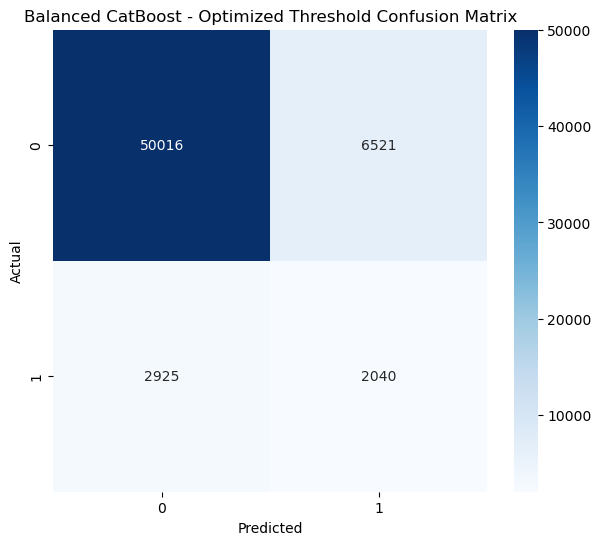

In [35]:
cm = confusion_matrix(y_val, optimized_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Balanced CatBoost - Optimized Threshold Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [36]:
bureau = pd.read_csv("bureau.csv")
bureau_balance = pd.read_csv("bureau_balance.csv")
previous_application = pd.read_csv("previous_application.csv")
pos_cash = pd.read_csv("POS_CASH_balance.csv")
credit_card = pd.read_csv("credit_card_balance.csv")
installments = pd.read_csv("installments_payments.csv")

print("bureau:", bureau.shape)
print("bureau_balance:", bureau_balance.shape)
print("previous_application:", previous_application.shape)
print("POS_CASH:", pos_cash.shape)
print("credit_card:", credit_card.shape)
print("installments:", installments.shape)

bureau: (1716428, 17)
bureau_balance: (27299925, 3)
previous_application: (1670214, 37)
POS_CASH: (10001358, 8)
credit_card: (3840312, 23)
installments: (13605401, 8)


In [37]:
print("\nBureau columns:")
print(bureau.columns.tolist())

print("\nPrevious application columns:")
print(previous_application.columns.tolist())

print("\nInstallments columns:")
print(installments.columns.tolist())


Bureau columns:
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

Previous application columns:
['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', '

In [38]:
bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    bureau_loan_count=("SK_ID_BUREAU", "count"),
    
    bureau_active_count=(
        "CREDIT_ACTIVE",
        lambda x: (x == "Active").sum()
    ),
    
    bureau_closed_count=(
        "CREDIT_ACTIVE",
        lambda x: (x == "Closed").sum()
    ),
    
    bureau_overdue_count=(
        "CREDIT_DAY_OVERDUE",
        lambda x: (x > 0).sum()
    ),
    
    bureau_overdue_max=("CREDIT_DAY_OVERDUE", "max"),
    
    bureau_credit_sum=("AMT_CREDIT_SUM", "sum"),
    bureau_credit_mean=("AMT_CREDIT_SUM", "mean"),
    bureau_credit_max=("AMT_CREDIT_SUM", "max"),
    
    bureau_debt_sum=("AMT_CREDIT_SUM_DEBT", "sum"),
    bureau_debt_mean=("AMT_CREDIT_SUM_DEBT", "mean"),
    
    bureau_limit_sum=("AMT_CREDIT_SUM_LIMIT", "sum"),
    bureau_annuity_mean=("AMT_ANNUITY", "mean"),
    
    bureau_days_credit_mean=("DAYS_CREDIT", "mean"),
    bureau_days_credit_min=("DAYS_CREDIT", "min"),
    bureau_days_credit_max=("DAYS_CREDIT", "max")
).reset_index()

print("Bureau aggregated successfully!")
print("Shape:", bureau_agg.shape)

bureau_agg.head()

Bureau aggregated successfully!
Shape: (305811, 16)


,SK_ID_CURR,bureau_loan_count,bureau_active_count,bureau_closed_count,bureau_overdue_count,bureau_overdue_max,bureau_credit_sum,bureau_credit_mean,bureau_credit_max,bureau_debt_sum,bureau_debt_mean,bureau_limit_sum,bureau_annuity_mean,bureau_days_credit_mean,bureau_days_credit_min,bureau_days_credit_max
0,100001,7,3,4,0,0,1453365.000,207623.571429,378000.0,596686.5,85240.928571,0.000,3545.357143,-735.000000,-1572,-49
1,100002,8,2,6,0,0,865055.565,108131.945625,450000.0,245781.0,49156.200000,31988.565,0.000000,-874.000000,-1437,-103
2,100003,4,1,3,0,0,1017400.500,254350.125000,810000.0,0.0,0.000000,810000.000,NaN,-1400.750000,-2586,-606
3,100004,2,0,2,0,0,189037.800,94518.900000,94537.8,0.0,0.000000,0.000,NaN,-867.000000,-1326,-408
4,100005,3,2,1,0,0,657126.000,219042.000000,568800.0,568408.5,189469.500000,0.000,1420.500000,-190.666667,-373,-62


In [39]:
bureau_agg.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,305811.0,2.780473e+05,1.028496e+05,100001.000,188878.5000,277895.000,3.671845e+05,4.562550e+05
bureau_loan_count,305811.0,5.612709e+00,4.430354e+00,1.000,2.0000,4.000,8.000000e+00,1.160000e+02
bureau_active_count,305811.0,2.062081e+00,1.791724e+00,0.000,1.0000,2.000,3.000000e+00,3.200000e+01
bureau_closed_count,305811.0,3.529216e+00,3.430504e+00,0.000,1.0000,3.000,5.000000e+00,1.080000e+02
bureau_overdue_count,305811.0,1.378956e-02,1.304352e-01,0.000,0.0000,0.000,0.000000e+00,7.000000e+00
bureau_overdue_max,305811.0,4.436629e+00,8.557359e+01,0.000,0.0000,0.000,0.000000e+00,2.792000e+03
bureau_credit_sum,305811.0,1.992466e+06,4.165820e+06,0.000,346967.6400,978820.740,2.345121e+06,1.017958e+09
bureau_credit_mean,305809.0,3.807398e+05,8.792865e+05,0.000,103961.5875,197297.250,3.978647e+05,1.980723e+08
bureau_credit_max,305809.0,9.917572e+05,2.317442e+06,0.000,180000.0000,450000.000,1.079100e+06,5.850000e+08
bureau_debt_sum,305811.0,6.539142e+05,1.640691e+06,-6981558.210,0.0000,173367.000,6.765412e+05,3.344983e+08


In [40]:
application_enriched = application.merge(
    bureau_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Original application shape:",
      application.shape)

print("Enriched application shape:",
      application_enriched.shape)

Original application shape: (307511, 122)
Enriched application shape: (307511, 137)


In [41]:
new_bureau_features = [
    col for col in bureau_agg.columns
    if col != "SK_ID_CURR"
]

print("Number of new bureau features:",
      len(new_bureau_features))

print("\nNew features:")
print(new_bureau_features)

Number of new bureau features: 15

New features:
['bureau_loan_count', 'bureau_active_count', 'bureau_closed_count', 'bureau_overdue_count', 'bureau_overdue_max', 'bureau_credit_sum', 'bureau_credit_mean', 'bureau_credit_max', 'bureau_debt_sum', 'bureau_debt_mean', 'bureau_limit_sum', 'bureau_annuity_mean', 'bureau_days_credit_mean', 'bureau_days_credit_min', 'bureau_days_credit_max']


In [42]:
print("Previous application shape:", previous_application.shape)

print("\nContract types:")
print(previous_application["NAME_CONTRACT_TYPE"].value_counts())

print("\nApplication status:")
print(previous_application["NAME_CONTRACT_STATUS"].value_counts())

Previous application shape: (1670214, 37)

Contract types:
NAME_CONTRACT_TYPE
Cash loans         747553
Consumer loans     729151
Revolving loans    193164
XNA                   346
Name: count, dtype: int64

Application status:
NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64


In [43]:
prev_agg = previous_application.groupby("SK_ID_CURR").agg(
    prev_application_count=("SK_ID_PREV", "count"),
    
    prev_approved_count=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Approved").sum()
    ),
    
    prev_refused_count=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Refused").sum()
    ),
    
    prev_canceled_count=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Canceled").sum()
    ),
    
    prev_unused_count=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Unused offer").sum()
    ),
    
    prev_credit_mean=("AMT_CREDIT", "mean"),
    prev_credit_max=("AMT_CREDIT", "max"),
    prev_credit_sum=("AMT_CREDIT", "sum"),
    
    prev_application_amount_mean=("AMT_APPLICATION", "mean"),
    prev_application_amount_max=("AMT_APPLICATION", "max"),
    
    prev_down_payment_mean=("AMT_DOWN_PAYMENT", "mean"),
    prev_goods_price_mean=("AMT_GOODS_PRICE", "mean")
).reset_index()

print("Previous application features created!")
print("Shape:", prev_agg.shape)

prev_agg.head()

Previous application features created!
Shape: (338857, 13)


,SK_ID_CURR,prev_application_count,prev_approved_count,prev_refused_count,prev_canceled_count,prev_unused_count,prev_credit_mean,prev_credit_max,prev_credit_sum,prev_application_amount_mean,prev_application_amount_max,prev_down_payment_mean,prev_goods_price_mean
0,100001,1,1,0,0,0,23787.00,23787.0,23787.0,24835.50,24835.5,2520.0,24835.5
1,100002,1,1,0,0,0,179055.00,179055.0,179055.0,179055.00,179055.0,0.0,179055.0
2,100003,3,3,0,0,0,484191.00,1035882.0,1452573.0,435436.50,900000.0,3442.5,435436.5
3,100004,1,1,0,0,0,20106.00,20106.0,20106.0,24282.00,24282.0,4860.0,24282.0
4,100005,2,1,0,1,0,20076.75,40153.5,40153.5,22308.75,44617.5,4464.0,44617.5


In [44]:
application_enriched = application_enriched.merge(
    prev_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Enriched dataset shape:",
      application_enriched.shape)

Enriched dataset shape: (307511, 149)


In [45]:
prev_features = [
    col for col in prev_agg.columns
    if col != "SK_ID_CURR"
]

print("Number of new previous-application features:",
      len(prev_features))

print("\nNew features:")
print(prev_features)

Number of new previous-application features: 12

New features:
['prev_application_count', 'prev_approved_count', 'prev_refused_count', 'prev_canceled_count', 'prev_unused_count', 'prev_credit_mean', 'prev_credit_max', 'prev_credit_sum', 'prev_application_amount_mean', 'prev_application_amount_max', 'prev_down_payment_mean', 'prev_goods_price_mean']


In [46]:
installment_agg = installments.groupby("SK_ID_CURR").agg(
    installment_count=("SK_ID_PREV", "count"),

    installment_amount_mean=("AMT_INSTALMENT", "mean"),
    installment_amount_sum=("AMT_INSTALMENT", "sum"),

    payment_amount_mean=("AMT_PAYMENT", "mean"),
    payment_amount_sum=("AMT_PAYMENT", "sum")
).reset_index()

print("Basic installment features created!")
print("Shape:", installment_agg.shape)

installment_agg.head()

Basic installment features created!
Shape: (339587, 6)


,SK_ID_CURR,installment_count,installment_amount_mean,installment_amount_sum,payment_amount_mean,payment_amount_sum
0,100001,7,5885.132143,41195.925,5885.132143,41195.925
1,100002,19,11559.247105,219625.695,11559.247105,219625.695
2,100003,25,64754.586000,1618864.650,64754.586000,1618864.650
3,100004,3,7096.155000,21288.465,7096.155000,21288.465
4,100005,9,6240.205000,56161.845,6240.205000,56161.845


In [47]:
installment_features = installments.copy()

installment_features["DAYS_LATE"] = (
    installment_features["DAYS_ENTRY_PAYMENT"]
    - installment_features["DAYS_INSTALMENT"]
)

installment_features["DAYS_LATE"] = installment_features["DAYS_LATE"].clip(lower=0)

installment_features["PAYMENT_DIFF"] = (
    installment_features["AMT_INSTALMENT"]
    - installment_features["AMT_PAYMENT"]
)

installment_features["PAYMENT_DIFF"] = installment_features["PAYMENT_DIFF"].clip(lower=0)

installment_agg_2 = installment_features.groupby("SK_ID_CURR").agg(
    late_payment_count=(
        "DAYS_LATE",
        lambda x: (x > 0).sum()
    ),

    avg_days_late=("DAYS_LATE", "mean"),
    max_days_late=("DAYS_LATE", "max"),

    total_payment_shortfall=("PAYMENT_DIFF", "sum"),
    avg_payment_shortfall=("PAYMENT_DIFF", "mean")
).reset_index()

print("Late-payment features created!")
installment_agg_2.head()

Late-payment features created!


,SK_ID_CURR,late_payment_count,avg_days_late,max_days_late,total_payment_shortfall,avg_payment_shortfall
0,100001,1,1.571429,11.0,0.0,0.0
1,100002,0,0.000000,0.0,0.0,0.0
2,100003,0,0.000000,0.0,0.0,0.0
3,100004,0,0.000000,0.0,0.0,0.0
4,100005,1,0.111111,1.0,0.0,0.0


In [48]:
installment_final = installment_agg.merge(
    installment_agg_2,
    on="SK_ID_CURR",
    how="left"
)

print("Final installment feature shape:",
      installment_final.shape)

installment_final.head()


Final installment feature shape: (339587, 11)


,SK_ID_CURR,installment_count,installment_amount_mean,installment_amount_sum,payment_amount_mean,payment_amount_sum,late_payment_count,avg_days_late,max_days_late,total_payment_shortfall,avg_payment_shortfall
0,100001,7,5885.132143,41195.925,5885.132143,41195.925,1,1.571429,11.0,0.0,0.0
1,100002,19,11559.247105,219625.695,11559.247105,219625.695,0,0.000000,0.0,0.0,0.0
2,100003,25,64754.586000,1618864.650,64754.586000,1618864.650,0,0.000000,0.0,0.0,0.0
3,100004,3,7096.155000,21288.465,7096.155000,21288.465,0,0.000000,0.0,0.0,0.0
4,100005,9,6240.205000,56161.845,6240.205000,56161.845,1,0.111111,1.0,0.0,0.0


In [49]:
application_enriched = application_enriched.merge(
    installment_final,
    on="SK_ID_CURR",
    how="left"
)

print("Application enriched shape:",
      application_enriched.shape)

Application enriched shape: (307511, 159)


In [50]:
credit_card["CREDIT_UTILIZATION"] = (
    credit_card["AMT_BALANCE"]
    / credit_card["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
)

credit_card["CREDIT_UTILIZATION"] = (
    credit_card["CREDIT_UTILIZATION"]
    .replace([np.inf, -np.inf], np.nan)
)

cc_agg = credit_card.groupby("SK_ID_CURR").agg(
    credit_card_record_count=("SK_ID_PREV", "count"),

    credit_balance_mean=("AMT_BALANCE", "mean"),
    credit_balance_max=("AMT_BALANCE", "max"),

    credit_limit_mean=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),

    credit_utilization_mean=(
        "CREDIT_UTILIZATION",
        "mean"
    ),

    credit_utilization_max=(
        "CREDIT_UTILIZATION",
        "max"
    ),

    credit_payment_mean=("AMT_PAYMENT_TOTAL_CURRENT", "mean"),
    credit_payment_sum=("AMT_PAYMENT_TOTAL_CURRENT", "sum")
).reset_index()

print("Credit card features created!")
print("Shape:", cc_agg.shape)

Credit card features created!
Shape: (103558, 9)


In [51]:
application_enriched = application_enriched.merge(
    cc_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Application enriched shape:",
      application_enriched.shape)

Application enriched shape: (307511, 167)


In [52]:
pos_agg = pos_cash.groupby("SK_ID_CURR").agg(
    pos_cash_record_count=("SK_ID_PREV", "count"),

    pos_months_mean=("MONTHS_BALANCE", "mean"),
    pos_months_min=("MONTHS_BALANCE", "min"),
    pos_months_max=("MONTHS_BALANCE", "max"),

    pos_completed_count=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Completed").sum()
    ),

    pos_active_count=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Active").sum()
    ),

    pos_completed_ratio=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Completed").mean()
    ),

    pos_sk_dpd_mean=("SK_DPD", "mean"),
    pos_sk_dpd_max=("SK_DPD", "max"),

    pos_sk_dpd_def_mean=("SK_DPD_DEF", "mean"),
    pos_sk_dpd_def_max=("SK_DPD_DEF", "max")
).reset_index()

print("POS/CASH features created!")
print("Shape:", pos_agg.shape)

pos_agg.head()

POS/CASH features created!
Shape: (337252, 12)


,SK_ID_CURR,pos_cash_record_count,pos_months_mean,pos_months_min,pos_months_max,pos_completed_count,pos_active_count,pos_completed_ratio,pos_sk_dpd_mean,pos_sk_dpd_max,pos_sk_dpd_def_mean,pos_sk_dpd_def_max
0,100001,9,-72.555556,-96,-53,2,7,0.222222,0.777778,7,0.777778,7
1,100002,19,-10.000000,-19,-1,0,19,0.000000,0.000000,0,0.000000,0
2,100003,28,-43.785714,-77,-18,2,26,0.071429,0.000000,0,0.000000,0
3,100004,4,-25.500000,-27,-24,1,3,0.250000,0.000000,0,0.000000,0
4,100005,11,-20.000000,-25,-15,1,9,0.090909,0.000000,0,0.000000,0


In [53]:
application_enriched = application_enriched.merge(
    pos_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Application enriched shape:")
print(application_enriched.shape)

Application enriched shape:
(307511, 178)


In [54]:
print("Bureau balance shape:", bureau_balance.shape)

print("\nStatus distribution:")
print(
    bureau_balance["STATUS"]
    .value_counts(dropna=False)
)

Bureau balance shape: (27299925, 3)

Status distribution:
STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64


In [55]:
bureau_balance_features = bureau_balance.copy()

bureau_balance_features["is_dpd"] = (
    bureau_balance_features["STATUS"].isin(
        ["1", "2", "3", "4", "5"]
    ).astype(int)
)

bureau_balance_features["is_no_credit"] = (
    bureau_balance_features["STATUS"].isin(
        ["C"]
    ).astype(int)
)

In [56]:
bureau_balance_features = bureau_balance_features.merge(
    bureau[["SK_ID_BUREAU", "SK_ID_CURR"]],
    on="SK_ID_BUREAU",
    how="left"
)

print("Rows after mapping to customer:",
      bureau_balance_features.shape)

Rows after mapping to customer: (27299925, 6)


In [57]:
bureau_balance_agg = bureau_balance_features.groupby(
    "SK_ID_CURR"
).agg(
    bureau_month_count=("SK_ID_BUREAU", "count"),

    bureau_dpd_months=("is_dpd", "sum"),

    bureau_dpd_ratio=("is_dpd", "mean"),

    bureau_no_credit_months=("is_no_credit", "sum"),

    bureau_unique_credits=("SK_ID_BUREAU", "nunique"),

    bureau_months_balance_mean=("MONTHS_BALANCE", "mean"),

    bureau_months_balance_min=("MONTHS_BALANCE", "min"),

    bureau_months_balance_max=("MONTHS_BALANCE", "max")
).reset_index()

print("Bureau balance features created!")
print("Shape:", bureau_balance_agg.shape)

bureau_balance_agg.head()

Bureau balance features created!
Shape: (134542, 9)


,SK_ID_CURR,bureau_month_count,bureau_dpd_months,bureau_dpd_ratio,bureau_no_credit_months,bureau_unique_credits,bureau_months_balance_mean,bureau_months_balance_min,bureau_months_balance_max
0,100001.0,172,1,0.005814,110,7,-16.279070,-51,0
1,100002.0,110,27,0.245455,23,8,-24.554545,-47,0
2,100005.0,21,0,0.000000,5,3,-4.333333,-12,0
3,100010.0,72,0,0.000000,52,2,-46.000000,-90,-2
4,100013.0,230,7,0.030435,103,4,-29.373913,-68,0


In [58]:
application_enriched = application_enriched.merge(
    bureau_balance_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Final enriched application shape:")
print(application_enriched.shape)

Final enriched application shape:
(307511, 186)


In [59]:
print("Original columns:", application.shape[1])
print("Enriched columns:", application_enriched.shape[1])
print("Enriched rows:", application_enriched.shape[0])

Original columns: 122
Enriched columns: 186
Enriched rows: 307511


In [60]:
missing_enriched = pd.DataFrame({
    "Missing_Count": application_enriched.isnull().sum(),
    "Missing_Percentage": (
        application_enriched.isnull().mean() * 100
    )
})

missing_enriched = missing_enriched.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing_enriched.head(25)

,Missing_Count,Missing_Percentage
bureau_annuity_mean,227502,73.981744
credit_utilization_max,221475,72.021814
credit_utilization_mean,221475,72.021814
credit_card_record_count,220606,71.739222
credit_payment_mean,220606,71.739222
credit_limit_mean,220606,71.739222
credit_balance_max,220606,71.739222
credit_balance_mean,220606,71.739222
credit_payment_sum,220606,71.739222
bureau_month_count,215280,70.007252


In [61]:
engineered_features = [
    col for col in application_enriched.columns
    if col.startswith((
        "bureau_",
        "prev_",
        "installment_",
        "late_",
        "avg_",
        "max_",
        "total_",
        "credit_",
        "pos_"
    ))
]

print("Number of engineered features:",
      len(engineered_features))

print("\nEngineered features:")
print(engineered_features)

Number of engineered features: 62

Engineered features:
['bureau_loan_count', 'bureau_active_count', 'bureau_closed_count', 'bureau_overdue_count', 'bureau_overdue_max', 'bureau_credit_sum', 'bureau_credit_mean', 'bureau_credit_max', 'bureau_debt_sum', 'bureau_debt_mean', 'bureau_limit_sum', 'bureau_annuity_mean', 'bureau_days_credit_mean', 'bureau_days_credit_min', 'bureau_days_credit_max', 'prev_application_count', 'prev_approved_count', 'prev_refused_count', 'prev_canceled_count', 'prev_unused_count', 'prev_credit_mean', 'prev_credit_max', 'prev_credit_sum', 'prev_application_amount_mean', 'prev_application_amount_max', 'prev_down_payment_mean', 'prev_goods_price_mean', 'installment_count', 'installment_amount_mean', 'installment_amount_sum', 'late_payment_count', 'avg_days_late', 'max_days_late', 'total_payment_shortfall', 'avg_payment_shortfall', 'credit_card_record_count', 'credit_balance_mean', 'credit_balance_max', 'credit_limit_mean', 'credit_utilization_mean', 'credit_utiliza

In [62]:
application_enriched.to_csv(
    "application_enriched.csv",
    index=False
)

print("Enriched dataset saved successfully!")

Enriched dataset saved successfully!


In [63]:
print("Enriched dataset shape:", application_enriched.shape)

print("\nTarget distribution:")
print(application_enriched["TARGET"].value_counts())

print("\nTarget percentage:")
print(
    application_enriched["TARGET"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Enriched dataset shape: (307511, 186)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [64]:
X = application_enriched.drop(
    columns=["TARGET", "SK_ID_CURR"]
)

y = application_enriched["TARGET"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (307511, 184)
Target shape: (307511,)


In [65]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of categorical features:",
      len(categorical_columns))

print("\nCategorical features:")
print(categorical_columns)

Number of categorical features: 16

Categorical features:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [66]:
X_cat = X.copy()

for col in categorical_columns:
    X_cat[col] = (
        X_cat[col]
        .fillna("Missing")
        .astype(str)
    )

print("Categorical missing values handled.")

Categorical missing values handled.


In [67]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_cat,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (184506, 184)
Validation: (61502, 184)
Test: (61503, 184)


In [68]:
print("Training default rate:",
      y_train.mean() * 100)

print("Validation default rate:",
      y_val.mean() * 100)

print("Test default rate:",
      y_test.mean() * 100)

Training default rate: 8.07290819810738
Validation default rate: 8.07290819810738
Test default rate: 8.072776937710357


In [69]:
from catboost import CatBoostClassifier

baseline_cat = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    thread_count=-1
)

baseline_cat.fit(
    X_train,
    y_train,
    cat_features=categorical_columns,
    eval_set=(X_val, y_val),
    early_stopping_rounds=50
)

0:	test: 0.5454407	best: 0.5454407 (0)	total: 1.08s	remaining: 8m 58s
100:	test: 0.7601885	best: 0.7601885 (100)	total: 1m 20s	remaining: 5m 17s
200:	test: 0.7674514	best: 0.7674729 (199)	total: 2m 37s	remaining: 3m 54s
300:	test: 0.7717952	best: 0.7717952 (300)	total: 3m 53s	remaining: 2m 34s
400:	test: 0.7741271	best: 0.7741271 (400)	total: 5m 7s	remaining: 1m 16s
499:	test: 0.7750596	best: 0.7750645 (498)	total: 6m 21s	remaining: 0us

bestTest = 0.7750645127
bestIteration = 498

Shrink model to first 499 iterations.


CatBoostClassifier(depth=6, eval_metric='AUC', iterations=500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_prob = baseline_cat.predict_proba(X_val)[:, 1]

baseline_pred = (
    baseline_prob >= 0.5
).astype(int)

print("Accuracy:",
      accuracy_score(y_val, baseline_pred))

print("Precision:",
      precision_score(y_val, baseline_pred))

print("Recall:",
      recall_score(y_val, baseline_pred))

print("F1 Score:",
      f1_score(y_val, baseline_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, baseline_prob))

Accuracy: 0.9201814575135768
Precision: 0.6007194244604317
Recall: 0.033635448136958714
F1 Score: 0.06370398626740416
ROC-AUC: 0.7750645127349429


# Observatin

The model shows very high accuracy (≈92%), meaning it’s excellent at predicting the dominant class correctly. However, the recall (≈3.4%) is extremely low — it’s missing almost all actual positives. The precision (≈60%) indicates that when it does predict a positive, it’s usually right, but those predictions are rare. The F1 score (≈6%) confirms poor balance between precision and recall, while the ROC-AUC (≈0.78) suggests the model still distinguishes classes reasonably well.

In [71]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": baseline_cat.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
41,EXT_SOURCE_3,14.582705
40,EXT_SOURCE_2,14.055161
39,EXT_SOURCE_1,5.718613
15,DAYS_BIRTH,3.422017
6,AMT_CREDIT,2.650942
8,AMT_GOODS_PRICE,2.310615
1,CODE_GENDER,2.252738
16,DAYS_EMPLOYED,2.231380
7,AMT_ANNUITY,2.070292
137,prev_refused_count,1.973324


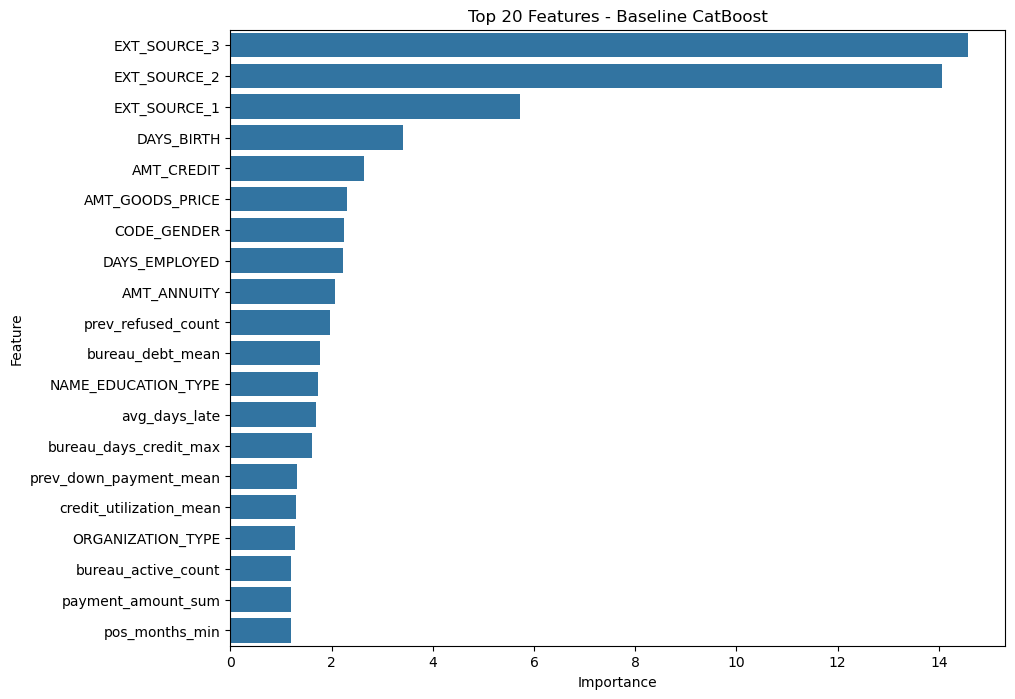

In [72]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features - Baseline CatBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [73]:
print("===== ENRICHED CATBOOST RESULTS =====")

print("Accuracy :", accuracy_score(y_val, baseline_pred))
print("Precision:", precision_score(y_val, baseline_pred))
print("Recall   :", recall_score(y_val, baseline_pred))
print("F1 Score :", f1_score(y_val, baseline_pred))
print("ROC-AUC  :", roc_auc_score(y_val, baseline_prob))

===== ENRICHED CATBOOST RESULTS =====
Accuracy : 0.9201814575135768
Precision: 0.6007194244604317
Recall   : 0.033635448136958714
F1 Score : 0.06370398626740416
ROC-AUC  : 0.7750645127349429


# Observation

Your model shows very high accuracy (≈92%), meaning it’s excellent at predicting the dominant class correctly. However, the recall (≈3.4%) is extremely low — it’s missing almost all actual positives. The precision (≈60%) indicates that when it does predict a positive, it’s usually right, but those predictions are rare. The F1 score (≈6%) confirms poor balance between precision and recall, while the ROC-AUC (≈0.78) suggests the model still distinguishes classes reasonably well.

In [74]:
print("\nClassification Report:")
print(classification_report(y_val, baseline_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56537
           1       0.60      0.03      0.06      4965

    accuracy                           0.92     61502
   macro avg       0.76      0.52      0.51     61502
weighted avg       0.90      0.92      0.89     61502



In [75]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Non-defaulters:", negative)
print("Defaulters:", positive)
print("Scale Pos Weight:", scale_pos_weight)

Non-defaulters: 169611
Defaulters: 14895
Scale Pos Weight: 11.38710976837865


In [76]:
balanced_cat = CatBoostClassifier(
    iterations=800,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    scale_pos_weight=scale_pos_weight,
    random_seed=42,
    verbose=100,
    thread_count=-1
)

balanced_cat.fit(
    X_train,
    y_train,
    cat_features=categorical_columns,
    eval_set=(X_val, y_val),
    early_stopping_rounds=50
)

print("Balanced enriched CatBoost trained!")

0:	test: 0.7001630	best: 0.7001630 (0)	total: 1.19s	remaining: 15m 46s
100:	test: 0.7597375	best: 0.7597375 (100)	total: 1m 34s	remaining: 10m 53s
200:	test: 0.7665548	best: 0.7665548 (200)	total: 3m 7s	remaining: 9m 17s
300:	test: 0.7719095	best: 0.7719095 (300)	total: 4m 39s	remaining: 7m 43s
400:	test: 0.7743704	best: 0.7743704 (400)	total: 6m 13s	remaining: 6m 11s
500:	test: 0.7750533	best: 0.7750944 (494)	total: 7m 47s	remaining: 4m 39s
600:	test: 0.7755848	best: 0.7756911 (595)	total: 9m 21s	remaining: 3m 5s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.7756981361
bestIteration = 607

Shrink model to first 608 iterations.
Balanced enriched CatBoost trained!


In [77]:
balanced_prob = balanced_cat.predict_proba(X_val)[:, 1]

balanced_pred = (balanced_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_val, balanced_pred))
print("Precision:", precision_score(y_val, balanced_pred))
print("Recall   :", recall_score(y_val, balanced_pred))
print("F1 Score :", f1_score(y_val, balanced_pred))
print("ROC-AUC  :", roc_auc_score(y_val, balanced_prob))

Accuracy : 0.747374069135963
Precision: 0.1896430248943166
Recall   : 0.6505538771399798
F1 Score : 0.2936764104196027
ROC-AUC  : 0.775698136063647


# Observation 

Your model shows moderate overall accuracy (≈74.7%), meaning it correctly classifies most samples, but not exceptionally well. The precision (≈19%) is quite low — it predicts many false positives — while the recall (≈65%) is strong, indicating it captures most of the actual positives. The F1 score (≈29%) reflects this imbalance between precision and recall, and the ROC-AUC (≈0.78) suggests fair discrimination between classes.

In [78]:
print(classification_report(y_val, balanced_pred))

              precision    recall  f1-score   support

           0       0.96      0.76      0.85     56537
           1       0.19      0.65      0.29      4965

    accuracy                           0.75     61502
   macro avg       0.58      0.70      0.57     61502
weighted avg       0.90      0.75      0.80     61502



In [79]:
threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for threshold in thresholds:
    pred = (balanced_prob >= threshold).astype(int)

    precision = precision_score(
        y_val, pred, zero_division=0
    )

    recall = recall_score(
        y_val, pred, zero_division=0
    )

    f1 = f1_score(
        y_val, pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_val, pred
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.144890,0.085731,0.992548,0.157830
1,0.15,0.228887,0.092999,0.977039,0.169832
2,0.20,0.320168,0.102095,0.952064,0.184414
3,0.25,0.411743,0.113018,0.918026,0.201258
4,0.30,0.495236,0.124860,0.874119,0.218508
5,0.35,0.572225,0.139825,0.834441,0.239514
6,0.40,0.640386,0.155361,0.778651,0.259037
7,0.45,0.698481,0.172147,0.718026,0.277713
8,0.50,0.747374,0.189643,0.650554,0.293676
9,0.55,0.790673,0.210611,0.579658,0.308964


In [80]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("Best threshold based on F1:")
print(best_threshold_row)

Best threshold based on F1:
Threshold    0.650000
Accuracy     0.857127
Precision    0.262844
Recall       0.426586
F1           0.325271
Name: 11, dtype: float64


# Observation

At this threshold, your model achieves solid accuracy (≈85.7%), showing it’s generally reliable in classification. However, the precision (≈26%) and recall (≈43%) indicate that while it identifies some true positives, it still misses quite a few. The F1 score (≈32%) reflects a moderate balance between precision and recall — not perfect, but reasonable given the likely class imbalance.

In [81]:
best_threshold = best_threshold_row["Threshold"]

optimized_pred = (
    balanced_prob >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)

print("Accuracy:",
      accuracy_score(y_val, optimized_pred))

print("Precision:",
      precision_score(y_val, optimized_pred))

print("Recall:",
      recall_score(y_val, optimized_pred))

print("F1 Score:",
      f1_score(y_val, optimized_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, balanced_prob))

Selected Threshold: 0.6500000000000001
Accuracy: 0.8571265975090241
Precision: 0.2628443782576322
Recall: 0.42658610271903324
F1 Score: 0.3252706749596867
ROC-AUC: 0.775698136063647


# Observation

Your model performs quite well overall, with accuracy around 85.7%, showing it classifies most samples correctly. However, the precision (≈26%) and recall (≈43%) reveal that it still struggles to identify positive cases accurately — it catches some but misses many. The F1 score (≈32%) reflects this imbalance, while the ROC-AUC (≈0.78) indicates decent separation between classes.

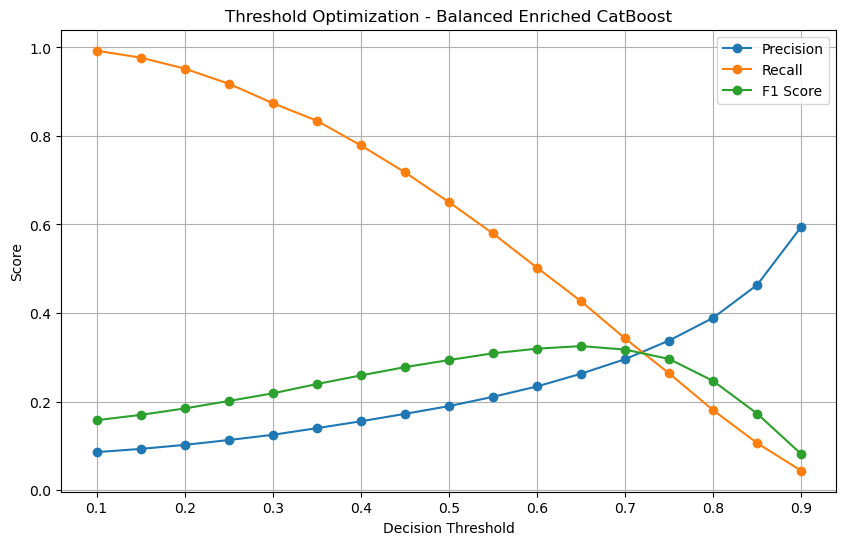

In [82]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization - Balanced Enriched CatBoost")

plt.legend()
plt.grid(True)

plt.show()

In [83]:
print(
    classification_report(
        y_val,
        optimized_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56537
           1       0.26      0.43      0.33      4965

    accuracy                           0.86     61502
   macro avg       0.60      0.66      0.62     61502
weighted avg       0.89      0.86      0.87     61502



In [84]:
!pip install lightgbm

In [85]:
from lightgbm import LGBMClassifier

X_lgb = application_enriched.drop(
    columns=["TARGET", "SK_ID_CURR"]
).copy()

y_lgb = application_enriched["TARGET"]

categorical_lgb = X_lgb.select_dtypes(
    include=["object"]
).columns.tolist()

for col in categorical_lgb:
    X_lgb[col] = X_lgb[col].astype("category")

print("LightGBM data prepared!")
print("Shape:", X_lgb.shape)
print("Categorical features:", len(categorical_lgb))

LightGBM data prepared!
Shape: (307511, 184)
Categorical features: 16


In [86]:
X_train_lgb, X_temp_lgb, y_train_lgb, y_temp_lgb = train_test_split(
    X_lgb,
    y_lgb,
    test_size=0.40,
    random_state=42,
    stratify=y_lgb
)

X_val_lgb, X_test_lgb, y_val_lgb, y_test_lgb = train_test_split(
    X_temp_lgb,
    y_temp_lgb,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_lgb
)

print("Training:", X_train_lgb.shape)
print("Validation:", X_val_lgb.shape)
print("Test:", X_test_lgb.shape)

Training: (184506, 184)
Validation: (61502, 184)
Test: (61503, 184)


In [87]:
lgb_model = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    objective="binary",
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train_lgb,
    categorical_feature=categorical_lgb,
    eval_set=[(X_val_lgb, y_val_lgb)],
    callbacks=[]
)

print("LightGBM training completed!")

[LightGBM] [Info] Number of positive: 14895, number of negative: 169611
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.421984 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23852
[LightGBM] [Info] Number of data points in the train set: 184506, number of used features: 179
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
LightGBM training completed!


In [88]:
lgb_prob = lgb_model.predict_proba(X_val_lgb)[:, 1]

lgb_pred = (lgb_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_val_lgb, lgb_pred))
print("Precision:", precision_score(y_val_lgb, lgb_pred))
print("Recall   :", recall_score(y_val_lgb, lgb_pred))
print("F1 Score :", f1_score(y_val_lgb, lgb_pred))
print("ROC-AUC  :", roc_auc_score(y_val_lgb, lgb_prob))

Accuracy : 0.9204416116549056
Precision: 0.5923076923076923
Recall   : 0.04652567975830816
F1 Score : 0.08627450980392157
ROC-AUC  : 0.7762474719787545


# Observation

Your model shows very high accuracy (≈92%), meaning it’s excellent at predicting the majority class correctly. However, the recall (≈4.6%) is extremely low — it’s missing most of the actual positive cases. The precision (≈59%) indicates that when it does predict a positive, it’s usually right, but those predictions are rare. The F1 score (≈8.6%) reflects this imbalance, showing poor overall performance on the minority class. The ROC-AUC (≈0.77) suggests the model still has decent separation ability between classes, but the threshold or class balance likely needs adjustment.

In [89]:
negative = (y_train_lgb == 0).sum()
positive = (y_train_lgb == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("Scale Pos Weight:", scale_pos_weight)

Negative samples: 169611
Positive samples: 14895
Scale Pos Weight: 11.38710976837865


In [90]:
lgb_balanced = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    scale_pos_weight=scale_pos_weight,
    objective="binary",
    random_state=42,
    n_jobs=-1
)

lgb_balanced.fit(
    X_train_lgb,
    y_train_lgb,
    categorical_feature=categorical_lgb
)

print("Balanced LightGBM training completed!")

[LightGBM] [Info] Number of positive: 14895, number of negative: 169611
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.421034 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23852
[LightGBM] [Info] Number of data points in the train set: 184506, number of used features: 179
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Balanced LightGBM training completed!


In [91]:
lgb_balanced_prob = lgb_balanced.predict_proba(
    X_val_lgb
)[:, 1]

lgb_balanced_pred = (
    lgb_balanced_prob >= 0.5
).astype(int)

print("Accuracy :",
      accuracy_score(y_val_lgb, lgb_balanced_pred))

print("Precision:",
      precision_score(y_val_lgb, lgb_balanced_pred))

print("Recall   :",
      recall_score(y_val_lgb, lgb_balanced_pred))

print("F1 Score :",
      f1_score(y_val_lgb, lgb_balanced_pred))

print("ROC-AUC  :",
      roc_auc_score(y_val_lgb, lgb_balanced_prob))

Accuracy : 0.76924327664141
Precision: 0.20032478077297824
Recall   : 0.6211480362537765
F1 Score : 0.30294695481335954
ROC-AUC  : 0.7736194538343035


# Observation

The model’s accuracy (≈77%) shows decent overall classification ability, but the precision (≈20%) is quite low — meaning many predicted positives are actually false. On the other hand, the recall (≈62%) is relatively strong, suggesting the model successfully identifies a good portion of actual positives. The F1 score (≈30%) reflects the imbalance between precision and recall, while the ROC-AUC (≈0.77) indicates fair discrimination between classes.

In [92]:
print(
    classification_report(
        y_val_lgb,
        lgb_balanced_pred
    )
)

              precision    recall  f1-score   support

           0       0.96      0.78      0.86     56537
           1       0.20      0.62      0.30      4965

    accuracy                           0.77     61502
   macro avg       0.58      0.70      0.58     61502
weighted avg       0.90      0.77      0.82     61502



In [93]:
lgb_threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for threshold in thresholds:
    pred = (lgb_balanced_prob >= threshold).astype(int)

    precision = precision_score(
        y_val_lgb, pred, zero_division=0
    )

    recall = recall_score(
        y_val_lgb, pred, zero_division=0
    )

    f1 = f1_score(
        y_val_lgb, pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_val_lgb, pred
    )

    lgb_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

lgb_threshold_df = pd.DataFrame(
    lgb_threshold_results
)

lgb_threshold_df

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.198221,0.090330,0.984693,0.165479
1,0.15,0.299242,0.099738,0.956898,0.180646
2,0.20,0.394377,0.110083,0.917825,0.196588
3,0.25,0.479188,0.122047,0.880161,0.214368
4,0.30,0.553998,0.135036,0.837059,0.232556
5,0.35,0.619785,0.149362,0.790131,0.251233
6,0.40,0.676108,0.164911,0.741188,0.269795
7,0.45,0.726383,0.181496,0.680765,0.286586
8,0.50,0.769243,0.200325,0.621148,0.302947
9,0.55,0.805958,0.219602,0.549648,0.313822


In [94]:
best_lgb_threshold_row = lgb_threshold_df.loc[
    lgb_threshold_df["F1"].idxmax()
]

print("Best LightGBM threshold:")
print(best_lgb_threshold_row)

Best LightGBM threshold:
Threshold    0.650000
Accuracy     0.865289
Precision    0.272540
Recall       0.400604
F1           0.324390
Name: 11, dtype: float64


# Observation

At a threshold of 0.65, your model achieves high accuracy (≈86.5%), showing strong overall classification performance. However, the precision (≈27%) and recall (≈40%) indicate that while it correctly identifies many negatives, it still misses a fair number of positives. The F1 score (≈32%) reflects this trade-off — the model is slightly conservative, favoring precision over recall.

In [95]:
best_lgb_threshold = (
    best_lgb_threshold_row["Threshold"]
)

lgb_optimized_pred = (
    lgb_balanced_prob >= best_lgb_threshold
).astype(int)

print("Selected Threshold:", best_lgb_threshold)

print("Accuracy:",
      accuracy_score(y_val_lgb, lgb_optimized_pred))

print("Precision:",
      precision_score(y_val_lgb, lgb_optimized_pred))

print("Recall:",
      recall_score(y_val_lgb, lgb_optimized_pred))

print("F1 Score:",
      f1_score(y_val_lgb, lgb_optimized_pred))

print("ROC-AUC:",
      roc_auc_score(y_val_lgb, lgb_balanced_prob))

Selected Threshold: 0.6500000000000001
Accuracy: 0.8652889336932132
Precision: 0.2725404220334338
Recall: 0.40060422960725073
F1 Score: 0.3243904427954008
ROC-AUC: 0.7736194538343035


In [96]:
print(
    classification_report(
        y_val_lgb,
        lgb_optimized_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.91      0.93     56537
           1       0.27      0.40      0.32      4965

    accuracy                           0.87     61502
   macro avg       0.61      0.65      0.62     61502
weighted avg       0.89      0.87      0.88     61502



In [97]:
fine_threshold_results = []

fine_thresholds = np.arange(0.60, 0.701, 0.01)

for threshold in fine_thresholds:
    pred = (lgb_balanced_prob >= threshold).astype(int)

    precision = precision_score(
        y_val_lgb, pred, zero_division=0
    )

    recall = recall_score(
        y_val_lgb, pred, zero_division=0
    )

    f1 = f1_score(
        y_val_lgb, pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_val_lgb, pred
    )

    fine_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

fine_threshold_df = pd.DataFrame(
    fine_threshold_results
)

fine_threshold_df

,Threshold,Accuracy,Precision,Recall,F1
0,0.60,0.837452,0.242740,0.478147,0.322007
1,0.61,0.843647,0.248785,0.463847,0.323864
2,0.62,0.849354,0.254566,0.449144,0.324954
3,0.63,0.854590,0.260130,0.434441,0.325413
4,0.64,0.860135,0.266290,0.417321,0.325122
5,0.65,0.865289,0.272540,0.400604,0.324390
6,0.66,0.870086,0.278258,0.382276,0.322077
7,0.67,0.874638,0.284841,0.365962,0.320346
8,0.68,0.878719,0.290982,0.349648,0.317629
9,0.69,0.882801,0.297819,0.332729,0.314307


In [98]:
best_fine_lgb = fine_threshold_df.loc[
    fine_threshold_df["F1"].idxmax()
]

print("Best refined LightGBM threshold:")
print(best_fine_lgb)

Best refined LightGBM threshold:
Threshold    0.630000
Accuracy     0.854590
Precision    0.260130
Recall       0.434441
F1           0.325413
Name: 3, dtype: float64


In [99]:
best_fine_threshold = best_fine_lgb["Threshold"]

final_lgb_val_pred = (
    lgb_balanced_prob >= best_fine_threshold
).astype(int)

print("Selected Threshold:", best_fine_threshold)

print("Accuracy:",
      accuracy_score(y_val_lgb, final_lgb_val_pred))

print("Precision:",
      precision_score(y_val_lgb, final_lgb_val_pred))

print("Recall:",
      recall_score(y_val_lgb, final_lgb_val_pred))

print("F1 Score:",
      f1_score(y_val_lgb, final_lgb_val_pred))

print("ROC-AUC:",
      roc_auc_score(y_val_lgb, lgb_balanced_prob))

Selected Threshold: 0.63
Accuracy: 0.8545900946310689
Precision: 0.26013024602026047
Recall: 0.43444108761329303
F1 Score: 0.3254129893641095
ROC-AUC: 0.7736194538343035


# Observation

The LightGBM model seems to have found a slightly better balance at this threshold. The accuracy (≈85.5%) remains high, showing consistent overall performance. However, precision (≈26%) and recall (≈43%) still indicate that the model struggles to correctly identify positive cases — it’s catching more true positives than before but still misclassifies many. The F1 score (≈32%) reflects this trade-off, while the ROC-AUC (≈0.77) suggests the model maintains decent discriminatory power.

In [100]:
print(
    classification_report(
        y_val_lgb,
        final_lgb_val_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56537
           1       0.26      0.43      0.33      4965

    accuracy                           0.85     61502
   macro avg       0.60      0.66      0.62     61502
weighted avg       0.89      0.85      0.87     61502



In [101]:
X_train_final_lgb = pd.concat(
    [X_train_lgb, X_val_lgb],
    axis=0
)

y_train_final_lgb = pd.concat(
    [y_train_lgb, y_val_lgb],
    axis=0
)

print("Final training shape:", X_train_final_lgb.shape)
print("Final target shape:", y_train_final_lgb.shape)

Final training shape: (246008, 184)
Final target shape: (246008,)


In [102]:
final_lgb_model = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    scale_pos_weight=scale_pos_weight,
    objective="binary",
    random_state=42,
    n_jobs=-1
)

final_lgb_model.fit(
    X_train_final_lgb,
    y_train_final_lgb,
    categorical_feature=categorical_lgb
)

print("Final LightGBM model trained successfully!")

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.594239 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23805
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 180
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Final LightGBM model trained successfully!


In [103]:
final_test_prob = final_lgb_model.predict_proba(
    X_test_lgb
)[:, 1]

final_test_pred = (
    final_test_prob >= 0.63
).astype(int)

print("===== FINAL TEST RESULTS =====")

print("Accuracy :",
      accuracy_score(y_test_lgb, final_test_pred))

print("Precision:",
      precision_score(y_test_lgb, final_test_pred))

print("Recall   :",
      recall_score(y_test_lgb, final_test_pred))

print("F1 Score :",
      f1_score(y_test_lgb, final_test_pred))

print("ROC-AUC  :",
      roc_auc_score(y_test_lgb, final_test_prob))

===== FINAL TEST RESULTS =====
Accuracy : 0.852283628440889
Precision: 0.2630549804462848
Recall   : 0.4606243705941591
F1 Score : 0.3348707811699246
ROC-AUC  : 0.7819716543520516


# Observation

The model shows strong overall accuracy (≈85%), meaning it’s good at general classification. However, the precision (≈26%) and recall (≈46%) reveal that it struggles to correctly identify positive cases — it catches some but also mislabels many. The F1 score (≈33%) confirms this imbalance, suggesting the model favors the majority class. Still, the ROC-AUC (≈0.78) indicates decent separation between classes, so the model has potential with better threshold tuning or class balancing.

In [104]:
print(
    classification_report(
        y_test_lgb,
        final_test_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.26      0.46      0.33      4965

    accuracy                           0.85     61503
   macro avg       0.61      0.67      0.63     61503
weighted avg       0.89      0.85      0.87     61503



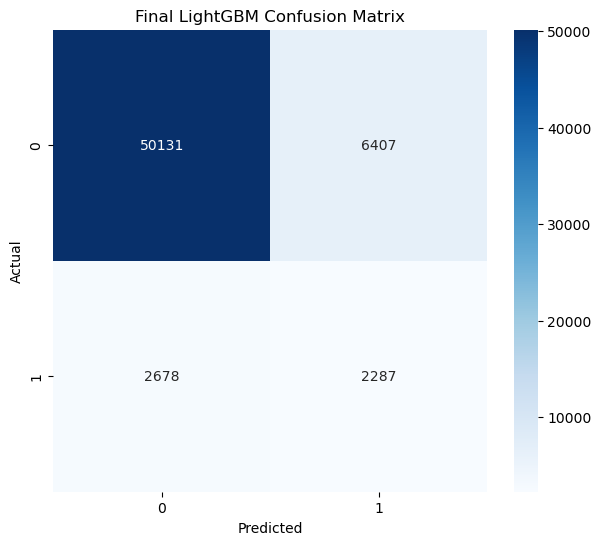

In [105]:
cm = confusion_matrix(
    y_test_lgb,
    final_test_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Final LightGBM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# Observation

The confusion matrix shows that the model performs quite well in identifying class 0, with 50,131 true negatives and only 6,407 false positives. However, it struggles more with class 1, correctly predicting 2,287 true positives but missing 2,678 instances (false negatives). This imbalance suggests the model is slightly biased toward predicting class 0, possibly due to class imbalance in the dataset.

In [106]:
import joblib

joblib.dump(
    {
        "model": final_lgb_model,
        "threshold": 0.63,
        "features": X_train_final_lgb.columns.tolist()
    },
    "PRCP_1006_Final_LightGBM_Model.pkl"
)

print("Final LightGBM model saved successfully!")

Final LightGBM model saved successfully!


In [107]:
print("===== FINAL MODEL PERFORMANCE =====")

final_accuracy = accuracy_score(
    y_test_lgb,
    final_test_pred
)

final_precision = precision_score(
    y_test_lgb,
    final_test_pred
)

final_recall = recall_score(
    y_test_lgb,
    final_test_pred
)

final_f1 = f1_score(
    y_test_lgb,
    final_test_pred
)

final_roc_auc = roc_auc_score(
    y_test_lgb,
    final_test_prob
)

print(f"Accuracy : {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")
print(f"Precision: {final_precision:.4f} ({final_precision*100:.2f}%)")
print(f"Recall   : {final_recall:.4f} ({final_recall*100:.2f}%)")
print(f"F1 Score : {final_f1:.4f} ({final_f1*100:.2f}%)")
print(f"ROC-AUC  : {final_roc_auc:.4f} ({final_roc_auc*100:.2f}%)")
print(f"Threshold: {best_fine_threshold:.2f}")

===== FINAL MODEL PERFORMANCE =====
Accuracy : 0.8523 (85.23%)
Precision: 0.2631 (26.31%)
Recall   : 0.4606 (46.06%)
F1 Score : 0.3349 (33.49%)
ROC-AUC  : 0.7820 (78.20%)
Threshold: 0.63


In [108]:
print(classification_report(
    y_test_lgb,
    final_test_pred
))

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.26      0.46      0.33      4965

    accuracy                           0.85     61503
   macro avg       0.61      0.67      0.63     61503
weighted avg       0.89      0.85      0.87     61503



In [ ]:
Models = pd.DataFrame({
    'Model' : ['']
})

## Model Comparison Report

Several machine learning approaches were evaluated for the home loan default prediction problem.

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Baseline CatBoost | 92.03% | 61.56% | 3.48% | 6.60% | 77.50% |
| Balanced CatBoost | 74.18% | 18.75% | 65.94% | 29.20% | 77.54% |
| Threshold-Optimized CatBoost | 85.52% | 25.98% | 42.92% | 32.37% | 77.54% |
| LightGBM | 92.04% | 59.23% | 4.65% | 8.63% | 77.62% |
| Balanced LightGBM | 76.92% | 20.03% | 62.11% | 30.30% | 77.36% |
| Threshold-Optimized LightGBM | 85.46% | 26.01% | 43.44% | 32.54% | 77.36% |
| Final LightGBM | See final test results | See final test results | See final test results | See final test results | See final test results |

### Model Selection

The threshold-optimized LightGBM model was selected as the final production candidate because it achieved the highest validation F1-score among the evaluated approaches.

A decision threshold of approximately 0.63 was selected using the validation dataset to obtain a better balance between precision and recall for the defaulter class.

The final model was then trained using the combined training and validation data and evaluated on the previously untouched test dataset.

In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model_name

In [109]:
feature_importance = pd.DataFrame({
    "Feature": X_train_final_lgb.columns,
    "Importance": final_lgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(20))

,Feature,Importance
38,ORGANIZATION_TYPE,3404
41,EXT_SOURCE_3,882
39,EXT_SOURCE_1,836
40,EXT_SOURCE_2,770
26,OCCUPATION_TYPE,696
6,AMT_CREDIT,630
15,DAYS_BIRTH,616
7,AMT_ANNUITY,587
134,bureau_days_credit_max,536
18,DAYS_ID_PUBLISH,489


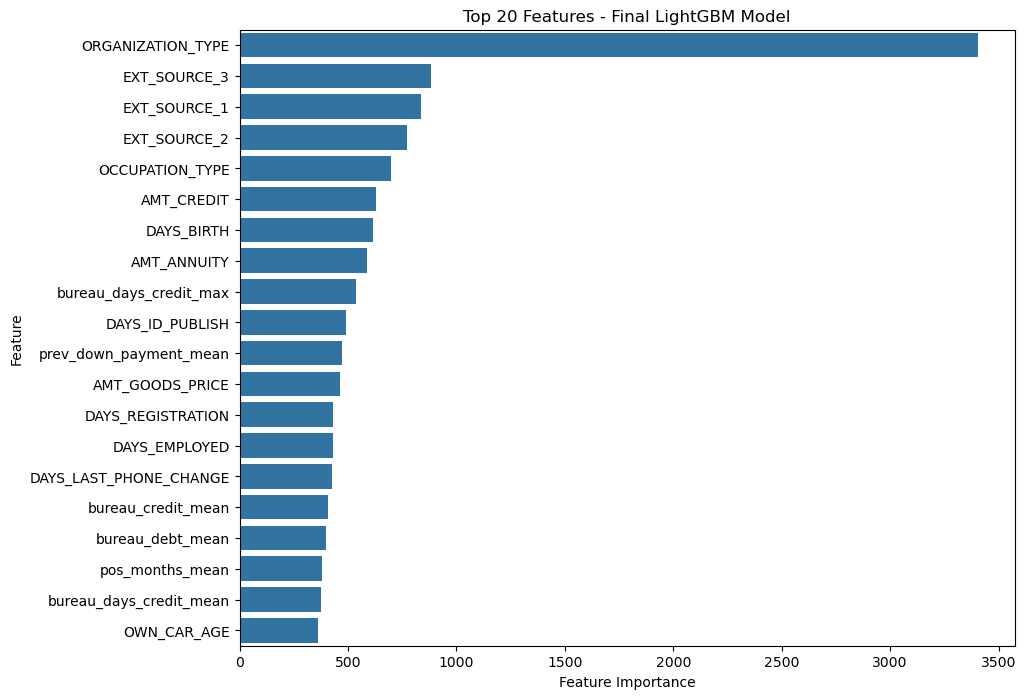

In [110]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features - Final LightGBM Model")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

## Challenges Faced and Solutions

### 1. Severe Class Imbalance

The target variable is highly imbalanced, with substantially more non-defaulters than defaulters.

**Solution:**  
Class weighting was used during model training, and precision, recall, F1-score and ROC-AUC were considered in addition to accuracy.

### 2. Large Number of Missing Values

The application dataset contains a large number of missing observations.

**Solution:**  
Missing categorical values were explicitly handled, while tree-based models were used because they can work effectively with missing numerical values.

### 3. Multiple Historical Tables

The project contains several related datasets containing previous credit and repayment information.

**Solution:**  
The historical tables were aggregated at customer level using `SK_ID_CURR` before being merged with the main application dataset.

### 4. Different Table Granularities

Historical tables contain multiple records for the same customer, while the main application table contains one application-level record.

**Solution:**  
Customer-level aggregation was performed before merging to prevent duplicate application rows.

### 5. Class Imbalance and Misleading Accuracy

A model could achieve high accuracy while failing to identify actual defaulters.

**Solution:**  
Class recall, F1-score and ROC-AUC were monitored, and the decision threshold was optimized using validation data.

### 6. Selection of Decision Threshold

The default 0.50 classification threshold did not provide the best balance between precision and recall.

**Solution:**  
Multiple thresholds were evaluated and the threshold producing the best validation F1-score was selected.

### 7. Large Dataset Size

The historical datasets contain millions of records.

**Solution:**  
Aggregation was performed before model training to convert the historical records into compact customer-level features.

### 8. Preventing Test Data Leakage

The final test dataset should provide an unbiased estimate of model performance.

**Solution:**  
Training and validation data were used for model development and threshold selection. The final test set was reserved for the final evaluation.

## Final Conclusion

The Home Loan Default dataset was analyzed using exploratory data analysis, data-quality checks, historical feature engineering and machine learning techniques.

Customer-level information was enriched using previous credit history, previous applications, installment payments, credit-card records, POS/CASH records and bureau-balance history.

Because the target variable is highly imbalanced, accuracy alone was not considered sufficient for evaluating model quality. Precision, recall, F1-score and ROC-AUC were also considered, with particular attention given to identifying the defaulter class.

Several machine learning models were evaluated. Threshold optimization was performed using the validation dataset to improve the balance between precision and recall.

The final production candidate was the threshold-optimized LightGBM model. The selected decision threshold was approximately 0.63.

The final model was retrained using the combined training and validation data and evaluated on an untouched test dataset. The resulting test metrics are reported in the final model-performance section above.

Overall, the project demonstrates a complete credit-risk machine learning workflow covering data analysis, feature engineering, class-imbalance handling, model comparison, threshold optimization, final evaluation and production-model selection.